# DSCI 552 — Homework 4

In [1]:
import os
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, auc)

warnings.filterwarnings("ignore")          # convergence / separation warnings are discussed in the text
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 552
COLORS = {"bending": "#1f77b4", "other": "#ff7f0e"}
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


In [2]:
# scikit-learn >= 1.8 deprecates `penalty`; this helper works with both old and new versions.
_NEW_API = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)


def logreg(penalty=None, C=1.0, **kw):
    """penalty=None -> plain (unpenalized) logistic regression; penalty='l1' -> L1-penalized."""
    if penalty is None:
        return LogisticRegression(C=np.inf, **kw) if _NEW_API else LogisticRegression(penalty=None, **kw)
    if penalty == "l1":
        return (LogisticRegression(C=C, l1_ratio=1.0, **kw) if _NEW_API
                else LogisticRegression(penalty="l1", C=C, **kw))
    raise ValueError(penalty)

## 1. Time Series Classification Part 1: Feature Creation/Extraction (code from Homework 3)

This part was submitted with Homework 3. The data loading, cleaning, train/test split, and feature extraction code is repeated here because Part 2 needs it.
The feature extractor is generalized: it can break every time series into `l` (approximately) equal-length pieces and compute the 7 time-domain features
(min, max, mean, median, std, 1st quartile, 3rd quartile) on each piece. With `l = 1` this gives the 42 features from Homework 3.

**Data cleaning:** `bending2/dataset4.csv` is space-delimited, `cycling/dataset9.csv` and `cycling/dataset14.csv` have a trailing comma in the last row,
and `sitting/dataset8.csv` has 479 rows instead of 480. The loader handles the first three; the missing sample is negligible.

In [3]:
DATA_DIR = "../HW3/AReM"   # path to the unzipped AReM folder

ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
COLUMNS = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
SERIES = COLUMNS[1:]


def load_instance(path):
    """Read one AReM file: skip '#' header lines, accept comma- or space-delimited rows."""
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            tokens = [t for t in re.split(r"[,\s]+", line) if t]
            rows.append([float(t) for t in tokens[:7]])
    return pd.DataFrame(rows, columns=COLUMNS)


def file_number(name):
    return int(re.findall(r"\d+", name)[0])


def is_test(activity, dataset):
    return dataset in ((1, 2) if activity in ("bending1", "bending2") else (1, 2, 3))


instances = []
for activity in ACTIVITIES:
    files = sorted((f for f in os.listdir(os.path.join(DATA_DIR, activity)) if f.endswith(".csv")), key=file_number)
    for f in files:
        k = file_number(f)
        instances.append({"activity": activity, "dataset": k,
                          "split": "test" if is_test(activity, k) else "train",
                          "data": load_instance(os.path.join(DATA_DIR, activity, f))})

meta = pd.DataFrame([{k: d[k] for k in ("activity", "dataset", "split")} for d in instances])
train_mask = (meta["split"] == "train").to_numpy()
test_mask = ~train_mask
y_bin = meta["activity"].str.startswith("bending").astype(int).to_numpy()   # 1 = bending, 0 = other
y_multi = meta["activity"].to_numpy()

print("instances:", len(instances), "| train:", train_mask.sum(), "| test:", test_mask.sum())
print("bending in train:", y_bin[train_mask].sum(), "of", train_mask.sum(),
      "| bending in test:", y_bin[test_mask].sum(), "of", test_mask.sum())

instances: 88 | train: 69 | test: 19
bending in train: 9 of 69 | bending in test: 4 of 19


In [4]:
FEATURE_FUNCS = {
    "min": np.min,
    "max": np.max,
    "mean": np.mean,
    "median": np.median,
    "std": lambda x: np.std(x, ddof=1),
    "1st_quart": lambda x: np.percentile(x, 25),
    "3rd_quart": lambda x: np.percentile(x, 75),
}


def extract_features(df, l=1, feature_names=tuple(FEATURE_FUNCS)):
    """Split each of the 6 series into l nearly equal parts and compute the features on each part."""
    feats = {}
    for i, col in enumerate(SERIES, start=1):
        for j, part in enumerate(np.array_split(df[col].to_numpy(), l), start=1):
            for name in feature_names:
                key = f"{name}{i}" if l == 1 else f"{name}{i}_part{j}"
                feats[key] = FEATURE_FUNCS[name](part)
    return feats


_feature_cache = {}


def features_for(l):
    """Feature matrix (88 rows, 42*l columns) for all instances, cached."""
    if l not in _feature_cache:
        _feature_cache[l] = pd.DataFrame([extract_features(d["data"], l) for d in instances])
    return _feature_cache[l]


features_for(1).head()

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,0.43,0.322605,0.00,0.50,4.0,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.50,0.965659,0.00,1.120,27.25,38.25,34.311292,35.0,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,0.47,0.289158,0.00,0.50,2.0,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.50,1.047259,0.00,1.145,27.67,38.50,33.024583,33.0,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,0.47,0.338690,0.00,0.50,6.5,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.43,0.550657,0.00,0.830,29.00,38.50,35.588458,36.0,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,0.50,0.630860,0.00,1.12,8.5,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.83,0.953730,0.43,1.300,20.00,38.67,33.493917,35.0,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,0.50,0.405469,0.43,0.71,3.0,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.50,0.928801,0.43,1.120,23.67,37.50,29.857083,30.0,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


**1(c)iv (from Homework 3):** the three selected features are **mean, standard deviation, and maximum**
(mean has the highest between-activity ANOVA F-statistic; std and max add information that is not redundant with the mean).

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Scatter plots of the selected features (time series 1, 2, 6), bending vs. other activities

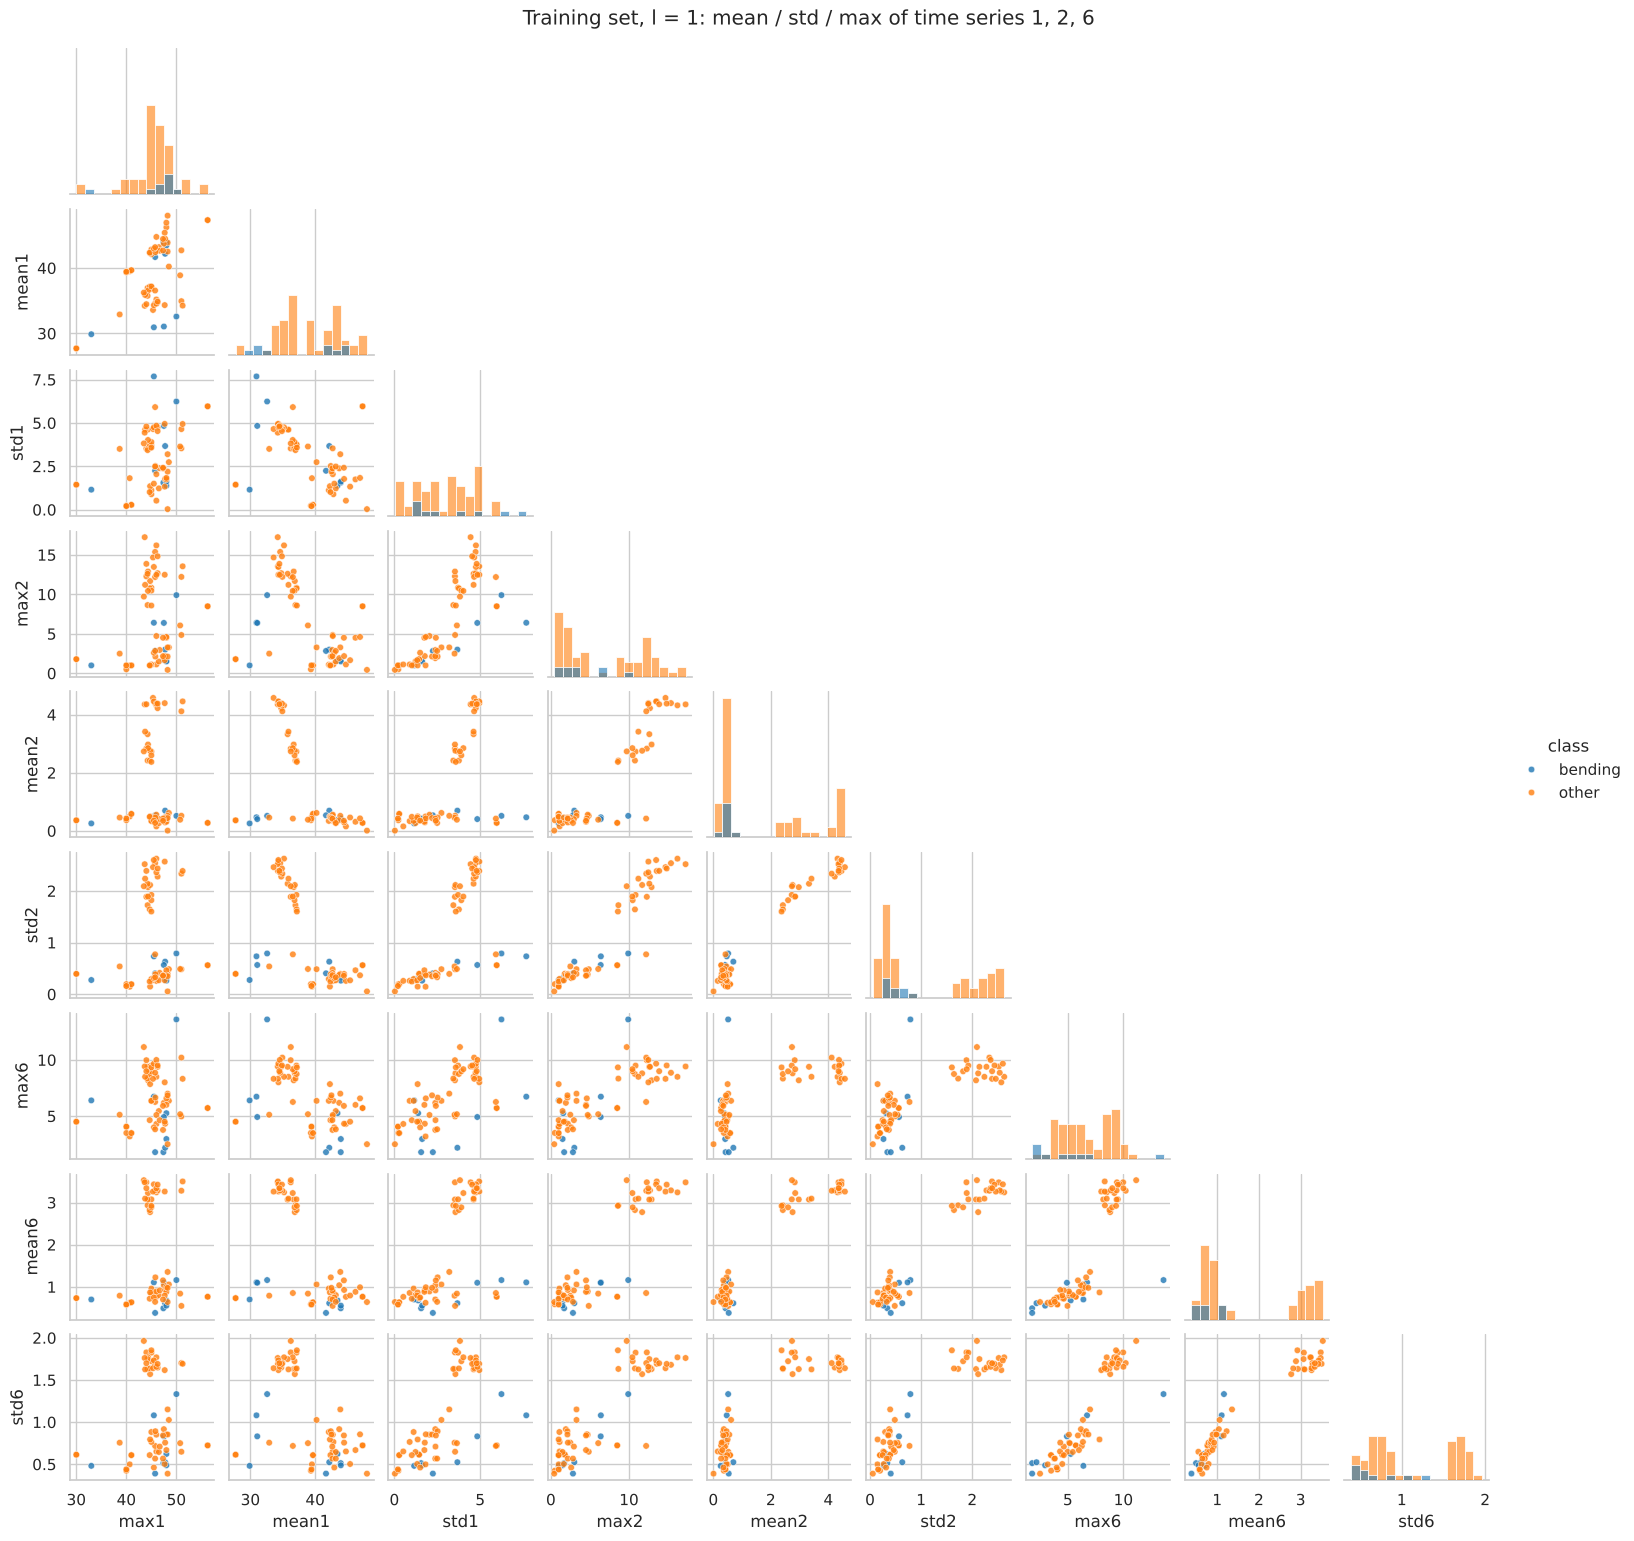

In [5]:
SELECTED = ["mean", "std", "max"]
train_labels = np.where(y_bin[train_mask] == 1, "bending", "other")


def selected_frame(l, series=(1, 2, 6)):
    X = features_for(l)[train_mask].reset_index(drop=True)
    cols = [c for c in X.columns
            if re.match(r"^(mean|std|max)(\d)", c) and int(re.match(r"^\D+(\d)", c).group(1)) in series]
    out = X[cols].copy()
    out["class"] = train_labels
    return out


g = sns.pairplot(selected_frame(1), hue="class", palette=COLORS, hue_order=["bending", "other"],
                 corner=True, height=1.7, plot_kws={"s": 22, "alpha": 0.8, "edgecolor": "white", "linewidth": 0.4},
                 diag_kind="hist", diag_kws={"bins": 15, "alpha": 0.6})
g.figure.suptitle("Training set, l = 1: mean / std / max of time series 1, 2, 6", y=1.01)
plt.show()

- **"Other" activities form two groups.** The dynamic activities (cycling, walking) have much larger values of `mean2`, `std2`, `max2`, `mean6`, and `std6`, so they form a separate cluster far away from bending.
- **Bending overlaps with the static activities.** In almost every plot, the bending points (blue) lie inside the cluster of the other static activities (lying, sitting, standing), so no single pair of these features separates bending perfectly.
- Some features separate bending partly. For example, `mean1` and `max6` tend to be lower for bending, but there are still "other" points mixed in.

So with only two features at a time, bending is **not** well separated from the other activities. A classifier needs to combine several features (which logistic regression does in iii).

#### ii. Break each time series into two halves and repeat

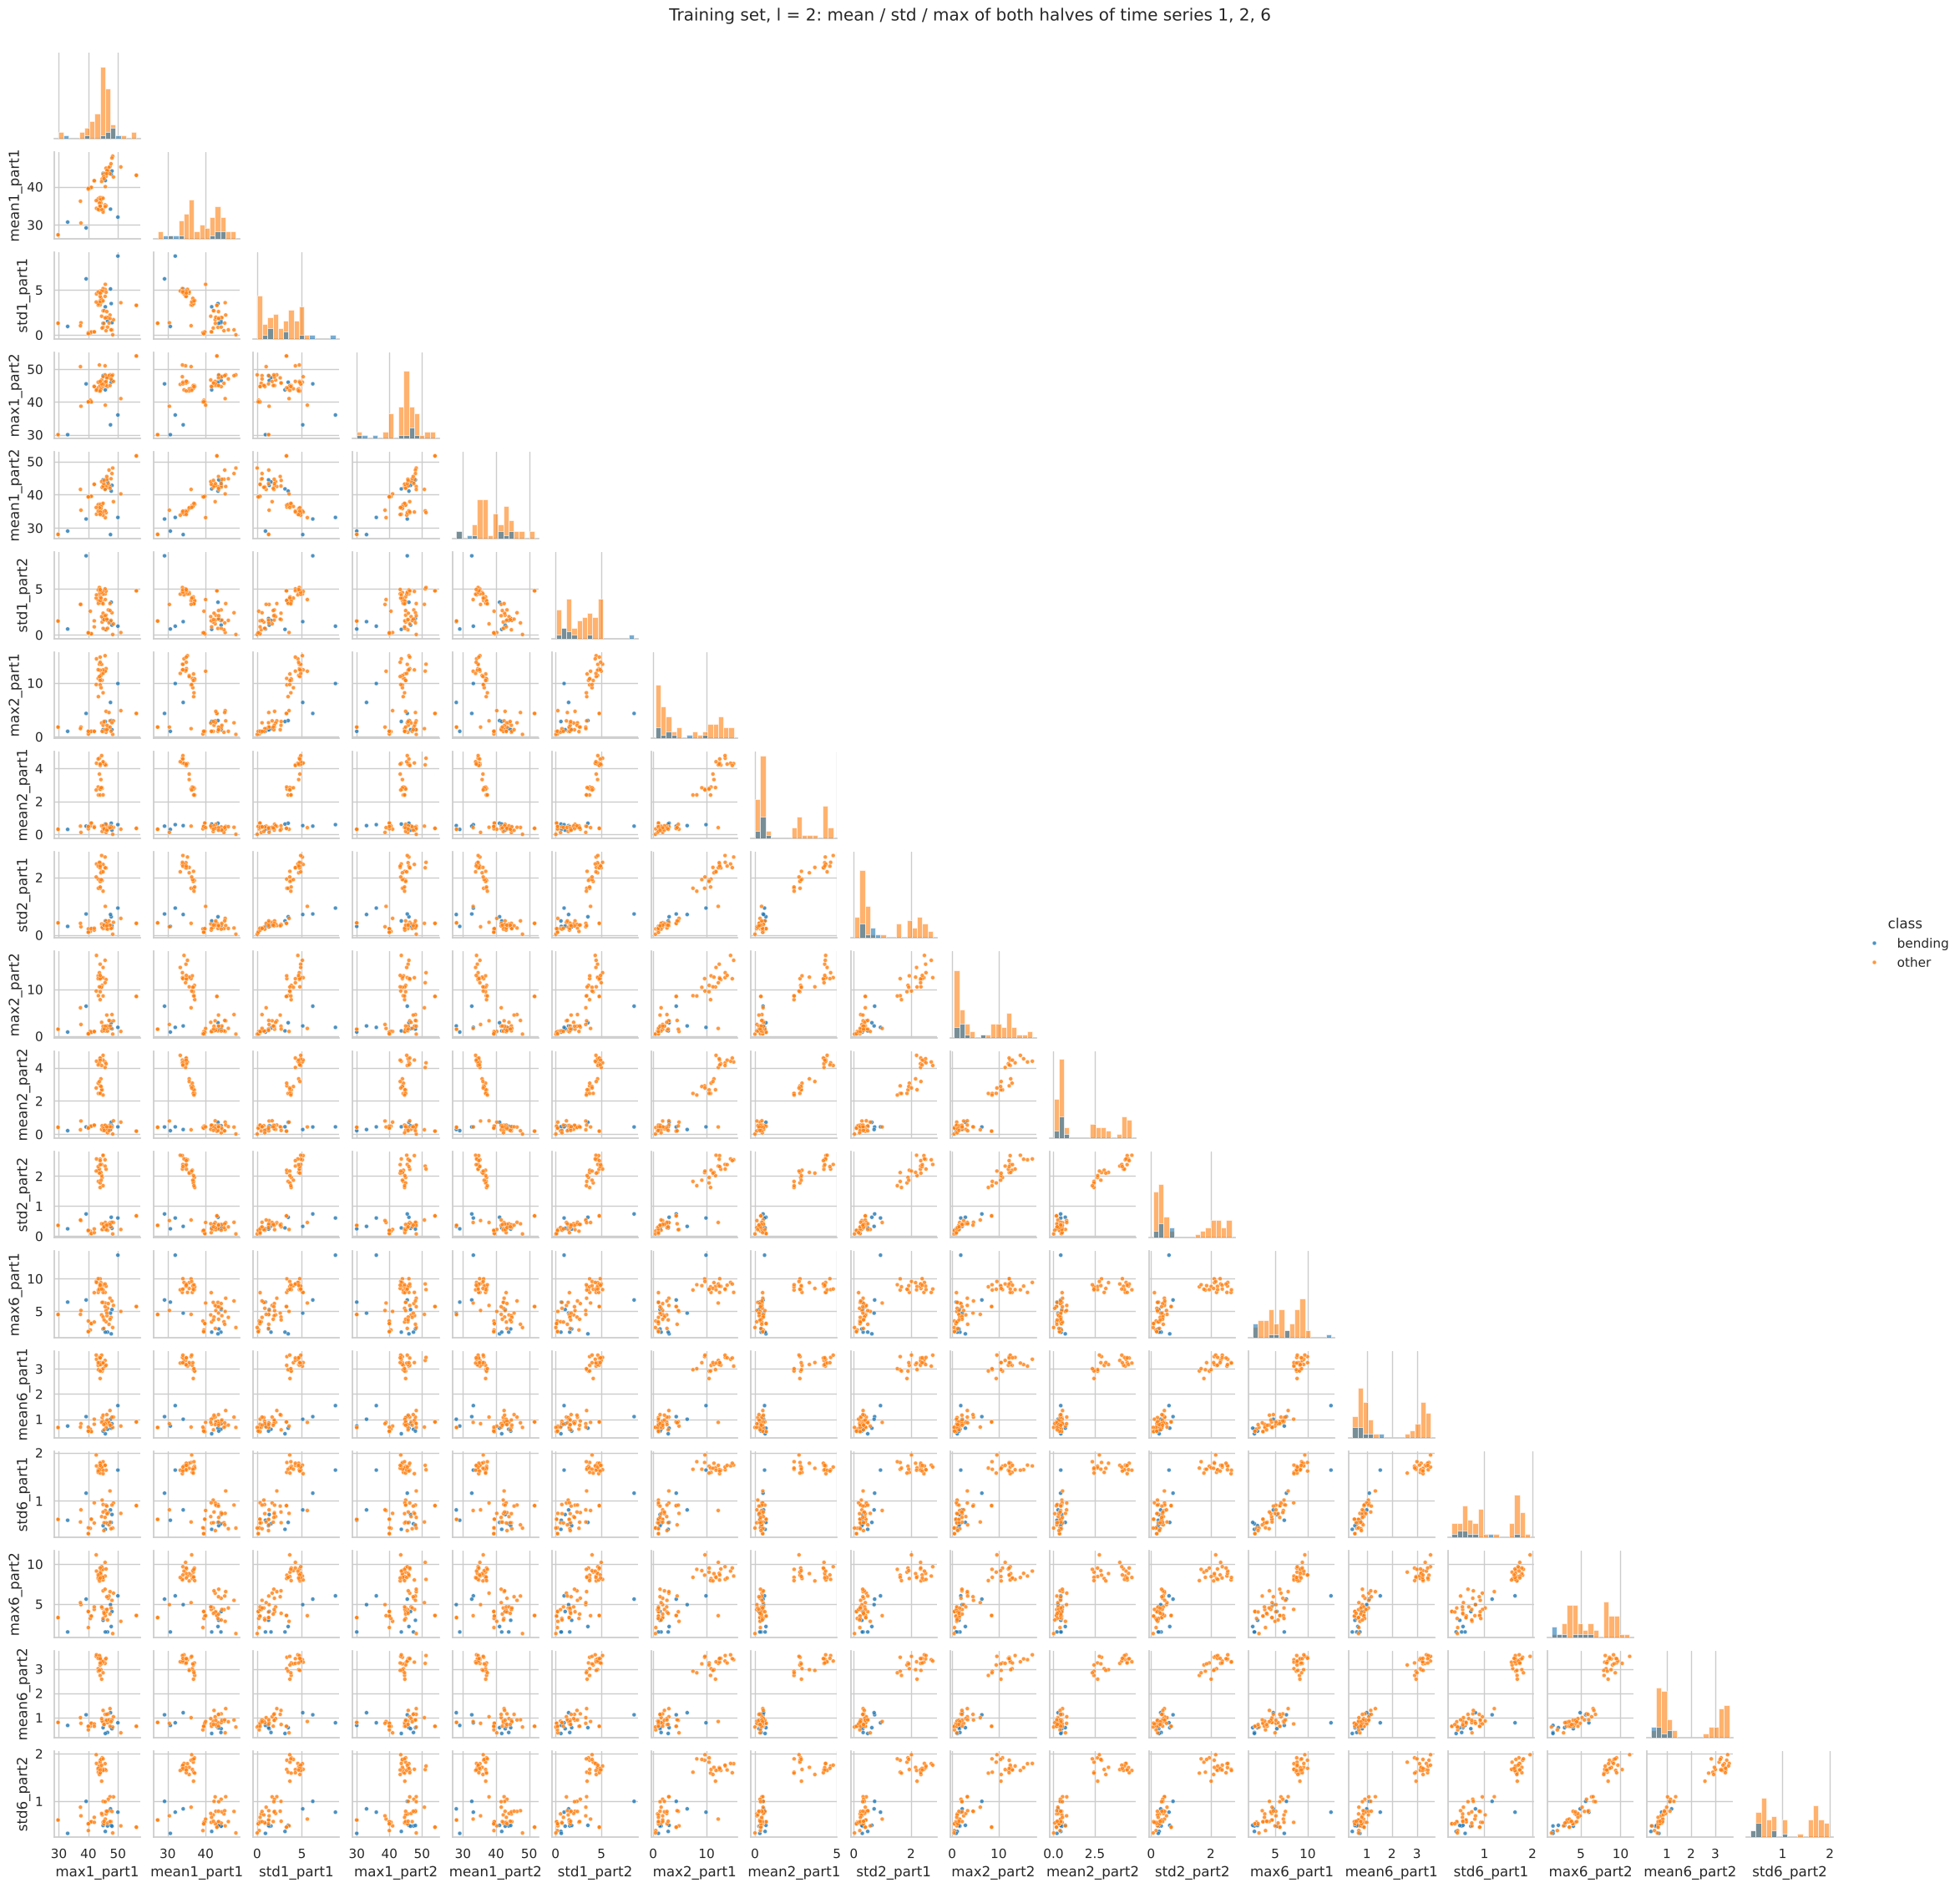

In [6]:
g = sns.pairplot(selected_frame(2), hue="class", palette=COLORS, hue_order=["bending", "other"],
                 corner=True, height=1.25, plot_kws={"s": 12, "alpha": 0.8, "edgecolor": "white", "linewidth": 0.3},
                 diag_kind="hist", diag_kws={"bins": 15, "alpha": 0.6})
g.figure.suptitle("Training set, l = 2: mean / std / max of both halves of time series 1, 2, 6", y=1.01)
plt.show()

There is **no considerable difference** from 2(a)i.
- For each feature, the values from the first half and from the second half are very similar. For example, `mean1_part1` vs. `mean1_part2` lie close to a straight line, because each activity is fairly stationary during the 2-minute recording.
- The pattern of the two classes is the same as in 2(a)i: the dynamic activities form a separate cluster, and bending still overlaps with the static activities in the 2-D plots.

Splitting the series doubles the number of features but adds little new information.

#### iii. Logistic regression with l ∈ {1, …, 20}, recursive feature elimination, and 5-fold cross-validation for (l, p)

**Setup.**
- For each l, every time series is broken into l pieces and all 7 time-domain features are computed for each piece, which gives 6 × 7 × l = 42l features.
- Logistic regression is unpenalized (C = ∞), as the footnote asks. `max_iter` is kept at its default (100); because the classes are almost linearly separable, this stops the optimizer before the coefficients diverge.
- For backward selection I use Recursive Feature Elimination (RFE, step = 1) and consider p ∈ {1, …, 20} features. Larger p is not useful: there are only 69 training instances, and only 9 of them are bending.
- Features are standardized before RFE, so that coefficient magnitudes (which RFE uses to rank features) are comparable.
- Because bending is the minority class (9 / 69 ≈ 13%), I use **stratified 5-fold cross-validation**. Stratified CV keeps the class proportions in each fold approximately the same as in the whole training set, so every fold contains bending instances.

**The right way and the wrong way to do cross-validation here.**
- **Wrong way:** run feature selection (RFE or p-value pruning) once on the *whole* training set, then use cross-validation only to evaluate the logistic regression fit on the already-selected features.
  The selected features have then already "seen" the validation folds, so the CV accuracy is optimistically biased (information leaks from the validation data into the model).
- **Right way:** treat feature selection as part of model fitting. Inside each fold, using **only that fold's training part**, fit the scaler, run RFE to choose the p features, and fit the logistic regression.
  Then evaluate on the held-out part. Breaking each instance into l pieces is done per instance and uses no label information, so it can be done before the split.
- I use the right way below. Because RFE with step = 1 removes one feature at a time, one RFE run per fold gives the complete elimination order, and the best p features for every p are read from that ranking.

In [7]:
L_VALUES = range(1, 21)
P_VALUES = range(1, 21)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_train_bin = y_bin[train_mask]

start = time.time()
cv_rfe = pd.DataFrame(index=pd.Index(L_VALUES, name="l"), columns=pd.Index(P_VALUES, name="p"), dtype=float)
for l in L_VALUES:
    X = features_for(l)[train_mask].to_numpy()
    fold_acc = np.zeros((skf.get_n_splits(), len(P_VALUES)))
    for f, (fit_idx, val_idx) in enumerate(skf.split(X, y_train_bin)):
        scaler = StandardScaler().fit(X[fit_idx])                     # fit on the fold's training part only
        X_fit, X_val = scaler.transform(X[fit_idx]), scaler.transform(X[val_idx])
        ranking = RFE(logreg(None), n_features_to_select=1, step=1).fit(X_fit, y_train_bin[fit_idx]).ranking_
        for k, p in enumerate(P_VALUES):
            keep = ranking <= p                                       # the p features RFE keeps
            model = logreg(None).fit(X_fit[:, keep], y_train_bin[fit_idx])
            fold_acc[f, k] = accuracy_score(y_train_bin[val_idx], model.predict(X_val[:, keep]))
    cv_rfe.loc[l] = fold_acc.mean(axis=0)
print(f"done in {time.time() - start:.0f} s")

best_acc = cv_rfe.to_numpy().max()
ties = [(l, p) for l in L_VALUES for p in P_VALUES if np.isclose(cv_rfe.loc[l, p], best_acc)]
best_l, best_p = ties[0]          # among ties, the simplest model: smallest l, then smallest p
print(f"Best CV accuracy = {best_acc:.4f}; pairs reaching it: {ties}")
print(f"Selected (l, p) = ({best_l}, {best_p})")

done in 176 s
Best CV accuracy = 0.9857; pairs reaching it: [(1, 6), (18, 3)]
Selected (l, p) = (1, 6)


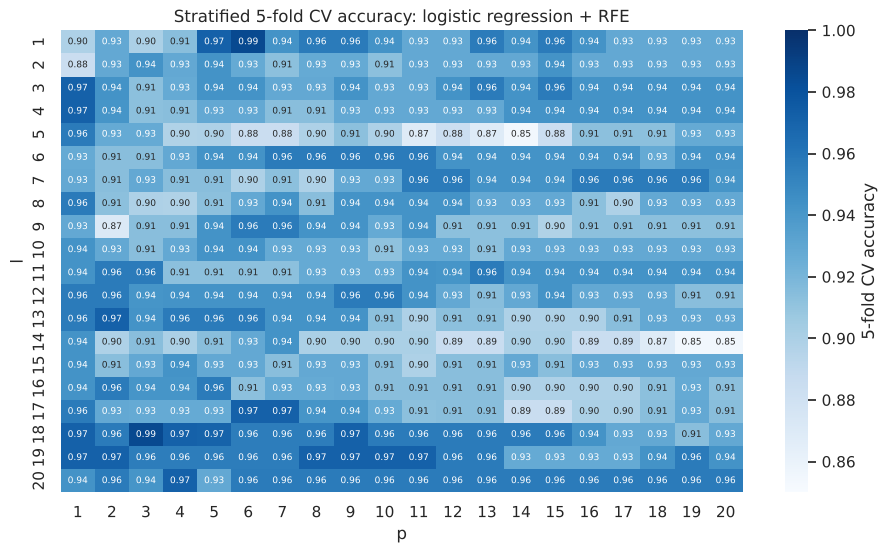

In [8]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(cv_rfe.astype(float), cmap="Blues", vmin=0.85, vmax=1.0, annot=True, fmt=".2f",
            annot_kws={"size": 6.5}, cbar_kws={"label": "5-fold CV accuracy"}, ax=ax)
ax.set_title("Stratified 5-fold CV accuracy: logistic regression + RFE")
plt.show()

#### iv. Confusion matrix, ROC, and AUC on the training data; coefficients and p-values

The final model uses the selected (l, p): the training features are standardized, RFE selects p features on the whole training set, and an unpenalized logistic regression is fit on them.

**p-values.** Because the classes are perfectly separated (see vi), the maximum likelihood estimate does not exist. `statsmodels` fails to converge and reports p-values of 1.000 for all coefficients.
So I compute **Wald p-values** for the fitted (early-stopped) coefficients: $SE = \sqrt{\operatorname{diag}\left((X^\top W X)^{-1}\right)}$ with $W = \operatorname{diag}(\hat p_i(1-\hat p_i))$, $z = \hat\beta / SE$, $p = 2\,(1-\Phi(|z|))$.

Selected features: ['3rd_quart1', 'max4', '1st_quart4', 'min5', 'max5', '1st_quart6']


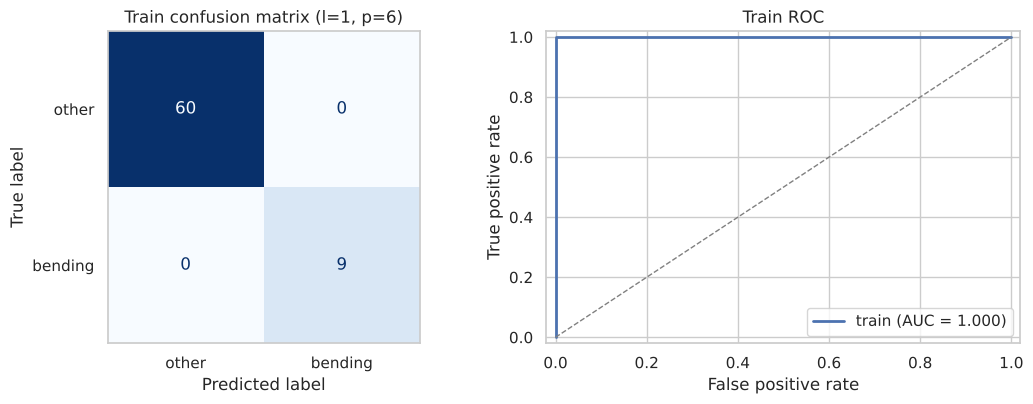

Train accuracy: 1.0


In [9]:
def wald_table(model, X, names):
    """Coefficients, standard errors, z-statistics and Wald p-values of a fitted binary logistic regression."""
    Xd = np.column_stack([np.ones(len(X)), np.asarray(X)])
    beta = np.r_[model.intercept_, model.coef_.ravel()]
    p_hat = 1 / (1 + np.exp(-Xd @ beta))
    info = Xd.T @ (Xd * (p_hat * (1 - p_hat))[:, None])
    se = np.sqrt(np.diag(np.linalg.pinv(info)))
    z = beta / se
    return pd.DataFrame({"beta": beta, "std_err": se, "z": z, "p_value": 2 * stats.norm.sf(np.abs(z))},
                        index=["intercept"] + list(names))


def show_confusion(y_true, y_pred, labels, display_labels, title, ax):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=display_labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
    ax.grid(False)
    return cm


def plot_roc(curves, title, ax):
    """curves: list of (label, y_true, score)."""
    for label, y_true, score in curves:
        fpr, tpr, _ = roc_curve(y_true, score)
        ax.plot(fpr, tpr, lw=2, label=f"{label} (AUC = {roc_auc_score(y_true, score):.3f})")
    ax.plot([0, 1], [0, 1], ls="--", lw=1, color="gray")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title=title, xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
    ax.legend(loc="lower right")


X_all = features_for(best_l)
scaler_rfe = StandardScaler().fit(X_all[train_mask])
Xtr_rfe = pd.DataFrame(scaler_rfe.transform(X_all[train_mask]), columns=X_all.columns)
Xte_rfe = pd.DataFrame(scaler_rfe.transform(X_all[test_mask]), columns=X_all.columns)
y_test_bin = y_bin[test_mask]

rfe_final = RFE(logreg(None), n_features_to_select=best_p, step=1).fit(Xtr_rfe, y_train_bin)
selected_features = list(X_all.columns[rfe_final.support_])
lr_rfe = logreg(None).fit(Xtr_rfe[selected_features], y_train_bin)
print("Selected features:", selected_features)

score_tr_rfe = lr_rfe.predict_proba(Xtr_rfe[selected_features])[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cm_train_rfe = show_confusion(y_train_bin, lr_rfe.predict(Xtr_rfe[selected_features]), [0, 1], ["other", "bending"],
                              f"Train confusion matrix (l={best_l}, p={best_p})", axes[0])
plot_roc([("train", y_train_bin, score_tr_rfe)], "Train ROC", axes[1])
plt.tight_layout(); plt.show()
print("Train accuracy:", accuracy_score(y_train_bin, lr_rfe.predict(Xtr_rfe[selected_features])))

In [10]:
print("Logistic regression parameters (features standardized with the training mean/std):")
wald_table(lr_rfe, Xtr_rfe[selected_features], selected_features).round(4)

Logistic regression parameters (features standardized with the training mean/std):


,beta,std_err,z,p_value
intercept,-12.1962,18.8461,-0.6471,0.5175
3rd_quart1,-3.9975,12.4298,-0.3216,0.7478
max4,3.4891,27.6446,0.1262,0.8996
1st_quart4,-3.4063,49.1192,-0.0693,0.9447
min5,6.9790,19.9187,0.3504,0.7261
max5,5.1031,23.2772,0.2192,0.8265
1st_quart6,-4.2901,54.6978,-0.0784,0.9375


In [11]:
# For reference: statsmodels on the same data reports complete separation
import statsmodels.api as sm
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sm_fit = sm.Logit(y_train_bin, sm.add_constant(Xtr_rfe[selected_features])).fit(disp=0, maxiter=100)
print("converged:", sm_fit.mle_retvals["converged"])
print(sm_fit.pvalues.round(4))

converged: False
const         0.9997
3rd_quart1    0.9998
max4          0.9999
1st_quart4    1.0000
min5          0.9999
max5          0.9999
1st_quart6    1.0000
dtype: float64


#### v. Test the classifier on the test set

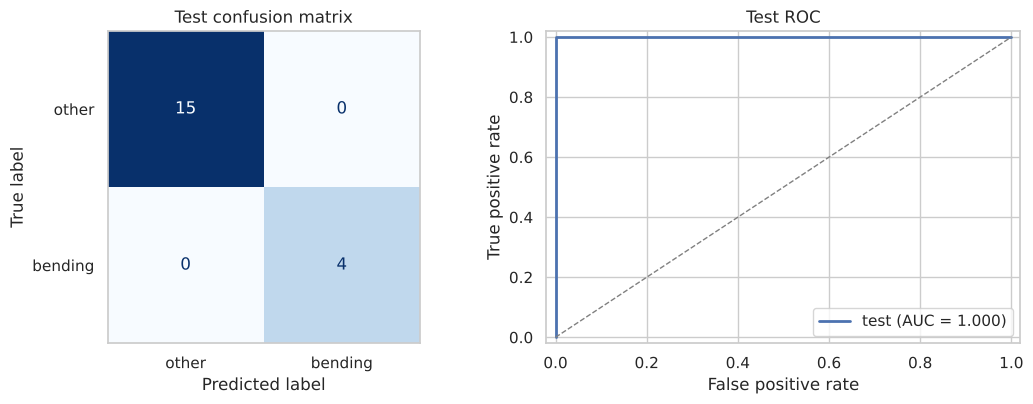

Cross-validation accuracy (l=1, p=6): 0.9857
Test accuracy:                              1.0000


In [12]:
pred_te_rfe = lr_rfe.predict(Xte_rfe[selected_features])
score_te_rfe = lr_rfe.predict_proba(Xte_rfe[selected_features])[:, 1]
test_acc_rfe = accuracy_score(y_test_bin, pred_te_rfe)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
show_confusion(y_test_bin, pred_te_rfe, [0, 1], ["other", "bending"], "Test confusion matrix", axes[0])
plot_roc([("test", y_test_bin, score_te_rfe)], "Test ROC", axes[1])
plt.tight_layout(); plt.show()

print(f"Cross-validation accuracy (l={best_l}, p={best_p}): {cv_rfe.loc[best_l, best_p]:.4f}")
print(f"Test accuracy:                              {test_acc_rfe:.4f}")

The test accuracy (**1.000**, all 19 test instances correct, test AUC = 1.0) is slightly **higher** than the cross-validation accuracy (**0.986**). The two are consistent.
The test set is very small (19 instances, 4 of them bending), so one misclassification changes the accuracy by about 5%, and a small difference between CV and test accuracy is expected.

#### vi. Are the classes well separated, causing instability?

**Yes.** With the selected 6 features, the two classes are **completely (linearly) separable** in the training data:
- The model classifies every training instance correctly, and the training AUC is 1.0.
- When classes are perfectly separable, the likelihood keeps increasing as the coefficients grow, so the maximum likelihood estimate does not exist (the coefficients go to ±∞).
  `statsmodels` reports "complete separation", does not converge, and gives p-values of about 1.0.
- The coefficients in iv are finite only because the optimizer stops early (`max_iter`, see footnote 5). Their standard errors are much larger than the estimates, so every Wald p-value is large (0.5–0.95).
  The values of $\hat\beta$ depend on when the optimizer stops, so they are unstable and should not be interpreted.

#### vii. Class imbalance and case-control sampling

**Yes, the classes are imbalanced.** The confusion matrices show 60 "other" vs. 9 bending instances in the training set (bending is only 13%), and 15 vs. 4 in the test set.
Because the classes are separable, the model above still makes no mistakes. However, imbalance can make a classifier favor the majority class, so I also build a model with case-control sampling, as the question asks.

**Case-control sampling.** I keep all bending instances (cases) and randomly sample the same number of non-bending instances (controls) from the training set, then fit logistic regression on the same l and the same selected features.
Case-control sampling changes the class proportions, so the intercept must be corrected. Only the intercept is affected; the slopes are unbiased:

$$\hat\beta_0^{*} = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi},$$

where $\pi$ is the true proportion of bending (estimated by its proportion in the full training set, 9/69) and $\tilde\pi$ is its proportion in the case-control sample (0.5).

pi = 0.1304, pi_tilde = 0.50
intercept before adjustment = -6.3475, after adjustment = -8.2447


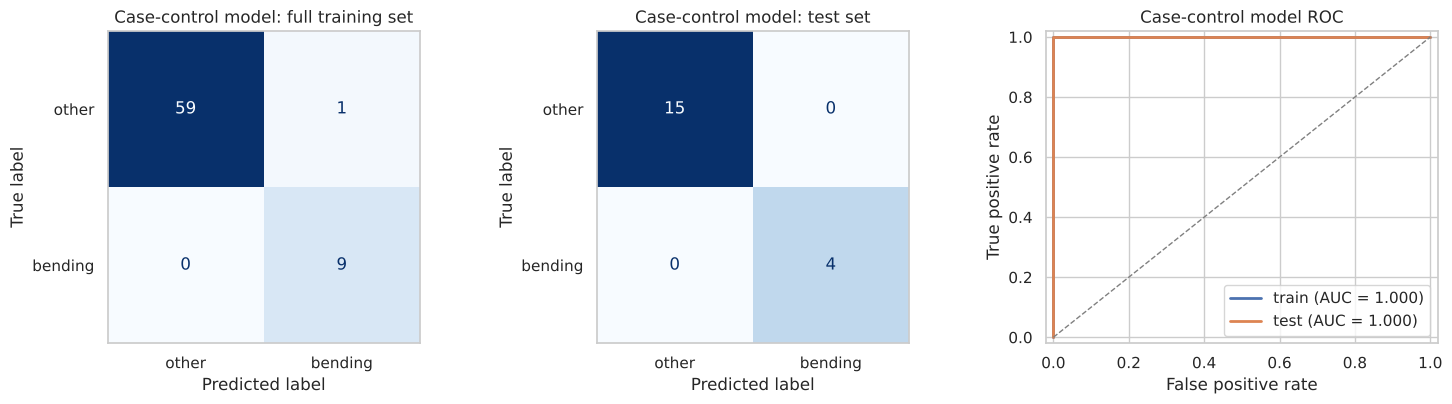

Train accuracy: 0.9855 | Test accuracy: 1.0


In [13]:
rng = np.random.default_rng(RANDOM_STATE)
case_idx = np.where(y_train_bin == 1)[0]
control_idx = rng.choice(np.where(y_train_bin == 0)[0], size=len(case_idx), replace=False)
cc_idx = np.r_[case_idx, control_idx]

lr_cc = logreg(None).fit(Xtr_rfe[selected_features].iloc[cc_idx], y_train_bin[cc_idx])
pi_true = y_train_bin.mean()
pi_sample = y_train_bin[cc_idx].mean()
intercept_raw = lr_cc.intercept_[0]
lr_cc.intercept_ = lr_cc.intercept_ + np.log(pi_true / (1 - pi_true)) - np.log(pi_sample / (1 - pi_sample))
print(f"pi = {pi_true:.4f}, pi_tilde = {pi_sample:.2f}")
print(f"intercept before adjustment = {intercept_raw:.4f}, after adjustment = {lr_cc.intercept_[0]:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
show_confusion(y_train_bin, lr_cc.predict(Xtr_rfe[selected_features]), [0, 1], ["other", "bending"],
               "Case-control model: full training set", axes[0])
show_confusion(y_test_bin, lr_cc.predict(Xte_rfe[selected_features]), [0, 1], ["other", "bending"],
               "Case-control model: test set", axes[1])
plot_roc([("train", y_train_bin, lr_cc.predict_proba(Xtr_rfe[selected_features])[:, 1]),
          ("test", y_test_bin, lr_cc.predict_proba(Xte_rfe[selected_features])[:, 1])],
         "Case-control model ROC", axes[2])
plt.tight_layout(); plt.show()
print("Train accuracy:", round(accuracy_score(y_train_bin, lr_cc.predict(Xtr_rfe[selected_features])), 4),
      "| Test accuracy:", round(accuracy_score(y_test_bin, lr_cc.predict(Xte_rfe[selected_features])), 4))

**Results of the case-control model (after the intercept adjustment):**
- Full training set: 68 of 69 correct (accuracy 0.986). One "other" instance is predicted as bending, and all 9 bending instances are correct.
- Test set: 19 of 19 correct (accuracy 1.0).
- AUC = 1.0 on both the training and test sets.

The model was fit on only 18 instances (9 cases + 9 controls), but it still separates the classes perfectly in terms of ranking (AUC = 1.0). The intercept adjustment makes the predicted probabilities reflect the true bending proportion again.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Repeat 2(a)iii with L1-penalized logistic regression

Instead of RFE, the L1 penalty performs variable selection by setting coefficients to exactly zero. I cross-validate both l ∈ {1, …, 20} and the budget C (the inverse of λ) over a grid of 11 values from 10⁻² to 10³,
using the same stratified 5-fold splits. Features are standardized inside each fold (in a pipeline), and the solver is liblinear.

done in 6 s
Best CV accuracy = 0.9857 at l = 11, C = 1


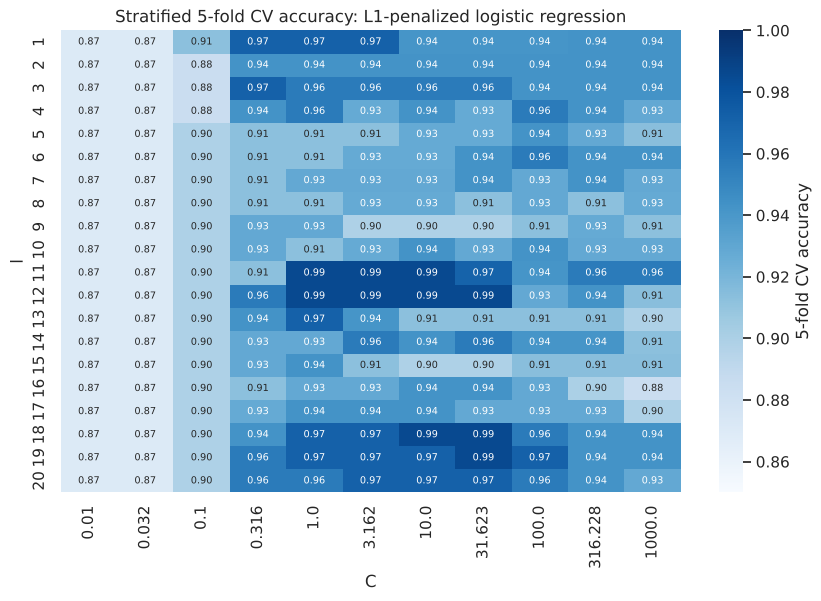

In [14]:
C_GRID = np.logspace(-2, 3, 11)
start = time.time()
cv_l1 = pd.DataFrame(index=pd.Index(L_VALUES, name="l"), columns=pd.Index(np.round(C_GRID, 3), name="C"), dtype=float)
for l in L_VALUES:
    X = features_for(l)[train_mask].to_numpy()
    for C_val, col in zip(C_GRID, cv_l1.columns):
        pipe = make_pipeline(StandardScaler(), logreg("l1", C=C_val, solver="liblinear"))
        cv_l1.loc[l, col] = cross_val_score(pipe, X, y_train_bin, cv=skf, scoring="accuracy").mean()
print(f"done in {time.time() - start:.0f} s")

best_acc_l1 = cv_l1.to_numpy().max()
pos = np.argwhere(np.isclose(cv_l1.to_numpy(), best_acc_l1))[0]      # smallest l, then smallest C (strongest penalty)
best_l_l1, best_C_l1 = list(L_VALUES)[pos[0]], C_GRID[pos[1]]
print(f"Best CV accuracy = {best_acc_l1:.4f} at l = {best_l_l1}, C = {best_C_l1:.3g}")

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(cv_l1.astype(float), cmap="Blues", vmin=0.85, vmax=1.0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"label": "5-fold CV accuracy"}, ax=ax)
ax.set_title("Stratified 5-fold CV accuracy: L1-penalized logistic regression")
plt.show()

Non-zero coefficients: 8 of 462


,beta (standardized features)
1st_quart5_part2,1.2556
max1_part6,-0.7820
min5_part10,0.7268
median5_part2,0.6413
median4_part8,-0.3118
max5_part1,0.2425
std6_part9,-0.1537
max6_part10,-0.0245


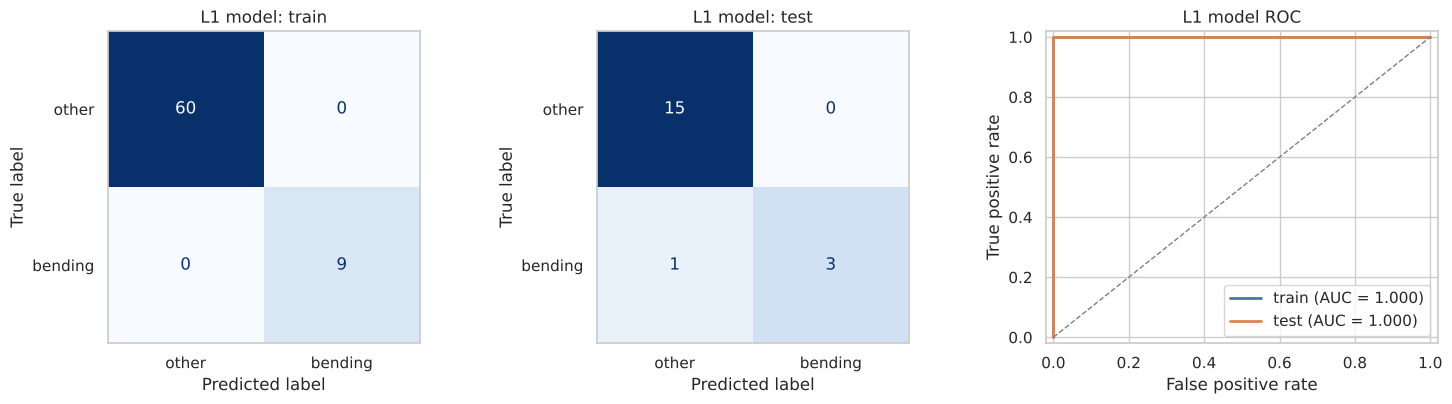

CV accuracy: 0.9857 | train accuracy: 1.0000 | test accuracy: 0.9474


In [15]:
X_all_l1 = features_for(best_l_l1)
l1_model = make_pipeline(StandardScaler(), logreg("l1", C=best_C_l1, solver="liblinear"))
l1_model.fit(X_all_l1[train_mask], y_train_bin)
coefs = pd.Series(l1_model[-1].coef_.ravel(), index=X_all_l1.columns)
print(f"Non-zero coefficients: {(coefs != 0).sum()} of {len(coefs)}")
display(coefs[coefs != 0].sort_values(key=np.abs, ascending=False).to_frame("beta (standardized features)").round(4))

pred_tr_l1 = l1_model.predict(X_all_l1[train_mask]); score_tr_l1 = l1_model.predict_proba(X_all_l1[train_mask])[:, 1]
pred_te_l1 = l1_model.predict(X_all_l1[test_mask]);  score_te_l1 = l1_model.predict_proba(X_all_l1[test_mask])[:, 1]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
show_confusion(y_train_bin, pred_tr_l1, [0, 1], ["other", "bending"], "L1 model: train", axes[0])
show_confusion(y_test_bin, pred_te_l1, [0, 1], ["other", "bending"], "L1 model: test", axes[1])
plot_roc([("train", y_train_bin, score_tr_l1), ("test", y_test_bin, score_te_l1)], "L1 model ROC", axes[2])
plt.tight_layout(); plt.show()
test_acc_l1 = accuracy_score(y_test_bin, pred_te_l1)
print(f"CV accuracy: {best_acc_l1:.4f} | train accuracy: {accuracy_score(y_train_bin, pred_tr_l1):.4f} | test accuracy: {test_acc_l1:.4f}")

#### ii. Compare L1-penalized logistic regression with variable selection using p-values / RFE

In [16]:
pd.DataFrame({
    "best l": [best_l, best_l_l1],
    "tuning parameter": [f"p = {best_p}", f"C = {best_C_l1:.3g}"],
    "features used": [best_p, int((coefs != 0).sum())],
    "CV accuracy": [cv_rfe.loc[best_l, best_p], best_acc_l1],
    "test accuracy": [test_acc_rfe, test_acc_l1],
    "test AUC": [roc_auc_score(y_test_bin, score_te_rfe), roc_auc_score(y_test_bin, score_te_l1)],
}, index=["RFE / p-value selection", "L1-penalized"]).round(4)

,best l,tuning parameter,features used,CV accuracy,test accuracy,test AUC
RFE / p-value selection,1,p = 6,6,0.9857,1.0000,1.0
L1-penalized,11,C = 1,8,0.9857,0.9474,1.0


**Which performs better?** The two methods perform about the same in this problem:
- Both reach the same best CV accuracy (0.986).
- Both have a test AUC of 1.0.
- RFE classifies all 19 test instances correctly. The L1 model misclassifies one bending test instance (test accuracy 0.947), but it still ranks every bending instance above every "other" instance (AUC = 1.0), so only the 0.5 threshold is slightly off.
- With only 19 test instances, a difference of one instance is not meaningful.

The L1 model is more stable: the penalty keeps the coefficients finite even though the classes are separable, so its coefficients are well defined and do not depend on when the optimizer stops. The unpenalized model with p-value selection has unstable coefficients and p-values (see 2(a)vi).

**Which is easier to implement?** **L1-penalized logistic regression** is much easier:
- Variable selection happens automatically in one convex fit, because the L1 penalty sets most coefficients to exactly zero (here 8 of 462).
- The only tuning parameter, C, is easy to cross-validate with standard tools (`cross_val_score` / `LogisticRegressionCV`).
- Selection with p-values or RFE needs a custom nested loop (selection must be repeated inside every CV fold), p-values are not provided by scikit-learn, and p-values are unreliable when the classes are separable.

### (c) Multi-class Classification (The Realistic Case)

#### i. L1-penalized multinomial regression for all 7 activities

The 7 classes are bending1, bending2, cycling, lying, sitting, standing, and walking. I choose (l, C) by stratified 5-fold CV in the same way as in 2(b)i, using the `saga` solver, which supports the L1 penalty for multinomial logistic regression.
(bending2 has only 4 training instances, so one fold has no bending2 instance; scikit-learn warns about this, but the folds are still as balanced as possible.)
This grid search takes a few minutes because saga converges slowly for large l.

done in 798 s
Best CV accuracy = 0.9143 at l = 2, C = 10.0


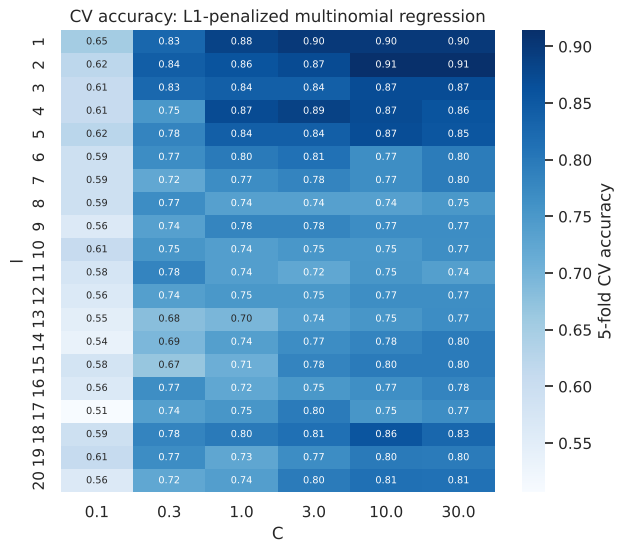

In [17]:
C_GRID_MULTI = np.array([0.1, 0.3, 1, 3, 10, 30])
y_train_multi, y_test_multi = y_multi[train_mask], y_multi[test_mask]

start = time.time()
cv_multi = pd.DataFrame(index=pd.Index(L_VALUES, name="l"), columns=pd.Index(C_GRID_MULTI, name="C"), dtype=float)
for l in L_VALUES:
    X = features_for(l)[train_mask].to_numpy()
    for C_val in C_GRID_MULTI:
        pipe = make_pipeline(StandardScaler(), logreg("l1", C=C_val, solver="saga", max_iter=3000))
        cv_multi.loc[l, C_val] = cross_val_score(pipe, X, y_train_multi, cv=skf, scoring="accuracy", n_jobs=-1).mean()
print(f"done in {time.time() - start:.0f} s")

best_acc_multi = cv_multi.to_numpy().max()
pos = np.argwhere(np.isclose(cv_multi.to_numpy(), best_acc_multi))[0]
best_l_multi, best_C_multi = list(L_VALUES)[pos[0]], C_GRID_MULTI[pos[1]]
print(f"Best CV accuracy = {best_acc_multi:.4f} at l = {best_l_multi}, C = {best_C_multi}")

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cv_multi.astype(float), cmap="Blues", annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"label": "5-fold CV accuracy"}, ax=ax)
ax.set_title("CV accuracy: L1-penalized multinomial regression")
plt.show()

**Confusion matrix and ROC for multiclass classification.**
- A multiclass **confusion matrix** is a K × K table: entry (i, j) counts the instances of true class i that were predicted as class j. The diagonal holds the correct predictions.
- ROC curves are defined for binary problems, so for K classes the usual approach is **one-vs-rest**: for each class k, treat k as positive and all other classes as negative, and draw the ROC curve using the predicted probability of class k.
  These K curves can be summarized by a **macro-average** AUC (the average of the K per-class AUCs) or a **micro-average** AUC (pool all K one-vs-rest decisions into one binary problem).

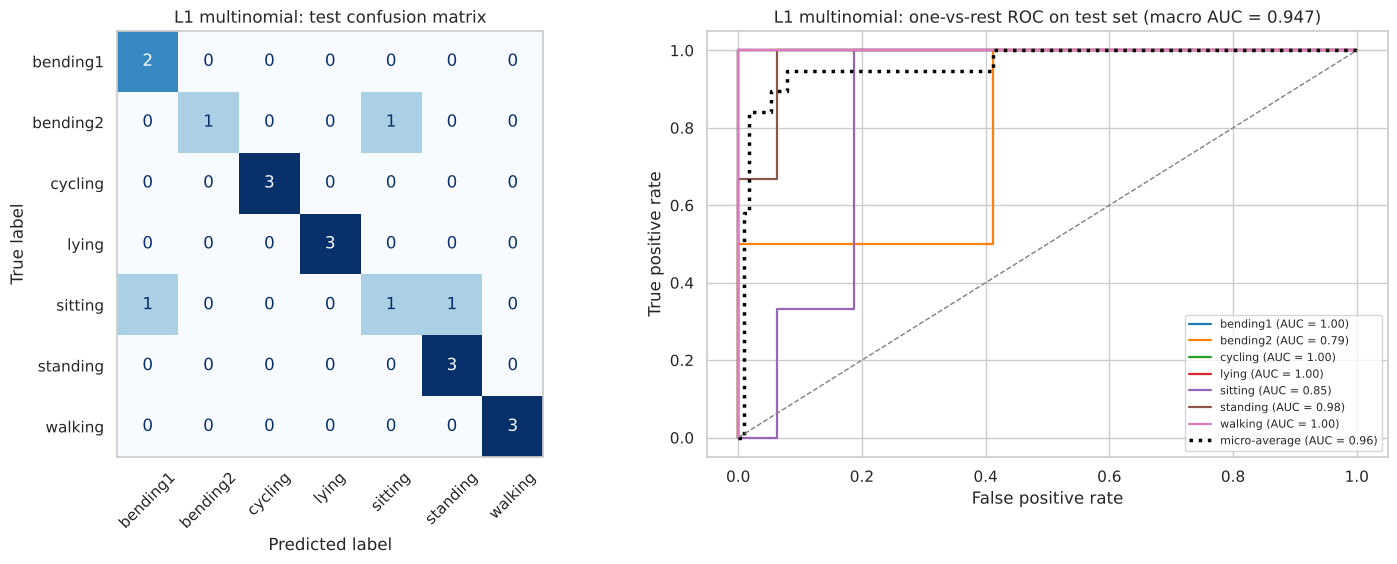

L1 multinomial: train accuracy = 1.0000, test accuracy = 0.8421, TEST ERROR = 0.1579


In [18]:
def multiclass_report(model, X_train, X_test, name):
    classes = list(model.classes_)
    pred_te = model.predict(X_test)
    prob_te = model.predict_proba(X_test)
    test_err = 1 - accuracy_score(y_test_multi, pred_te)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
    show_confusion(y_test_multi, pred_te, classes, classes, f"{name}: test confusion matrix", axes[0])
    axes[0].tick_params(axis="x", rotation=45)

    Y = label_binarize(y_test_multi, classes=classes)
    palette = sns.color_palette("tab10", len(classes))
    for k, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, k], prob_te[:, k])
        axes[1].plot(fpr, tpr, lw=1.6, color=palette[k], label=f"{cls} (AUC = {auc(fpr, tpr):.2f})")
    fpr, tpr, _ = roc_curve(Y.ravel(), prob_te.ravel())
    micro = auc(fpr, tpr)
    macro = roc_auc_score(Y, prob_te, average="macro")
    axes[1].plot(fpr, tpr, lw=2.5, ls=":", color="black", label=f"micro-average (AUC = {micro:.2f})")
    axes[1].plot([0, 1], [0, 1], ls="--", lw=1, color="gray")
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate",
                title=f"{name}: one-vs-rest ROC on test set (macro AUC = {macro:.3f})")
    axes[1].legend(loc="lower right", fontsize=8)
    plt.tight_layout(); plt.show()
    print(f"{name}: train accuracy = {accuracy_score(y_train_multi, model.predict(X_train)):.4f}, "
          f"test accuracy = {1 - test_err:.4f}, TEST ERROR = {test_err:.4f}")
    return test_err, macro


X_multi = features_for(best_l_multi)
multi_l1 = make_pipeline(StandardScaler(), logreg("l1", C=best_C_multi, solver="saga", max_iter=3000))
multi_l1.fit(X_multi[train_mask], y_train_multi)
err_multi_l1, auc_multi_l1 = multiclass_report(multi_l1, X_multi[train_mask], X_multi[test_mask], "L1 multinomial")

#### ii. Naïve Bayes classifiers (Gaussian and Multinomial)

l is chosen by stratified 5-fold CV, as before (Naïve Bayes has no penalty parameter to tune).
- **Gaussian NB** models each feature within each class as a normal distribution; it is used on the raw features.
- **Multinomial NB** models features as non-negative counts or frequencies. All AReM features are already non-negative, but they are on very different scales,
  so I rescale each feature to [0, 1] with a MinMaxScaler fit on the training fold (values in the test set are clipped to [0, 1]).

In [19]:
nb_models = {
    "Gaussian NB": lambda: GaussianNB(),
    "Multinomial NB": lambda: make_pipeline(MinMaxScaler(clip=True), MultinomialNB()),
}
cv_nb = pd.DataFrame(index=pd.Index(L_VALUES, name="l"), columns=list(nb_models), dtype=float)
for l in L_VALUES:
    X = features_for(l)[train_mask].to_numpy()
    for name, make in nb_models.items():
        cv_nb.loc[l, name] = cross_val_score(make(), X, y_train_multi, cv=skf, scoring="accuracy").mean()

best_l_nb = {name: int(cv_nb[name].astype(float).idxmax()) for name in nb_models}
print("Best l:", best_l_nb)
cv_nb.T.round(3)

Best l: {'Gaussian NB': 1, 'Multinomial NB': 5}


l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Gaussian NB,0.869,0.855,0.751,0.696,0.724,0.710,0.693,0.605,0.636,0.711,0.622,0.638,0.625,0.580,0.596,0.595,0.580,0.523,0.567,0.552
Multinomial NB,0.680,0.723,0.708,0.710,0.753,0.753,0.724,0.738,0.724,0.738,0.710,0.724,0.738,0.724,0.724,0.724,0.724,0.710,0.724,0.738


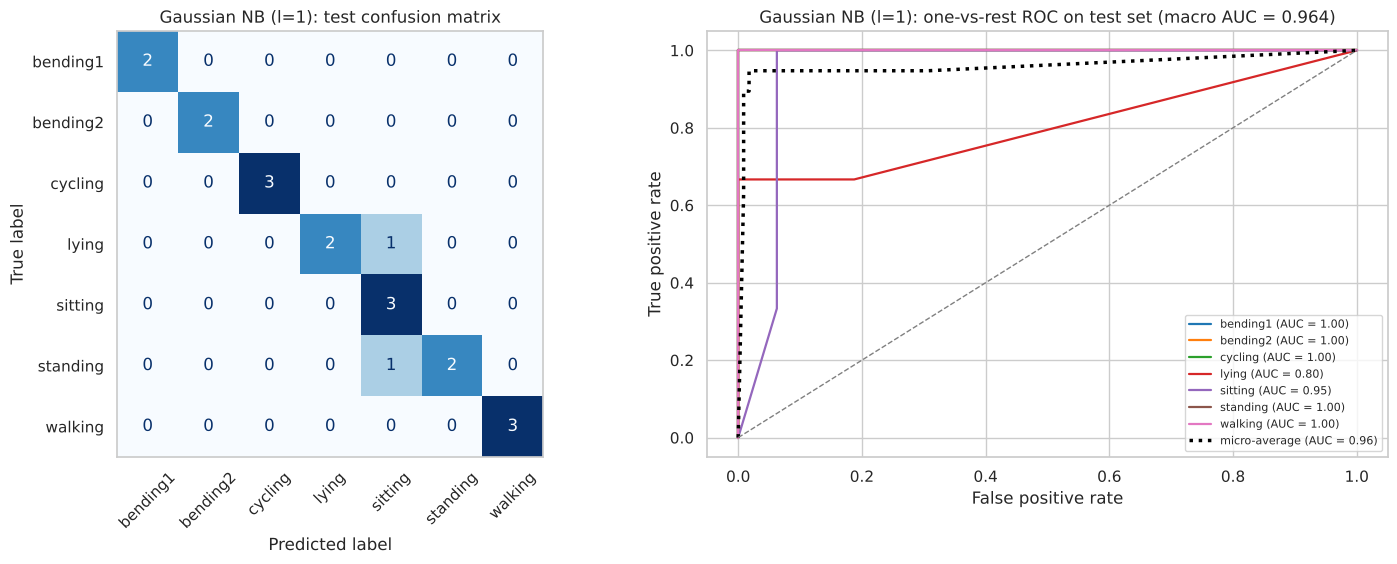

Gaussian NB (l=1): train accuracy = 1.0000, test accuracy = 0.8947, TEST ERROR = 0.1053


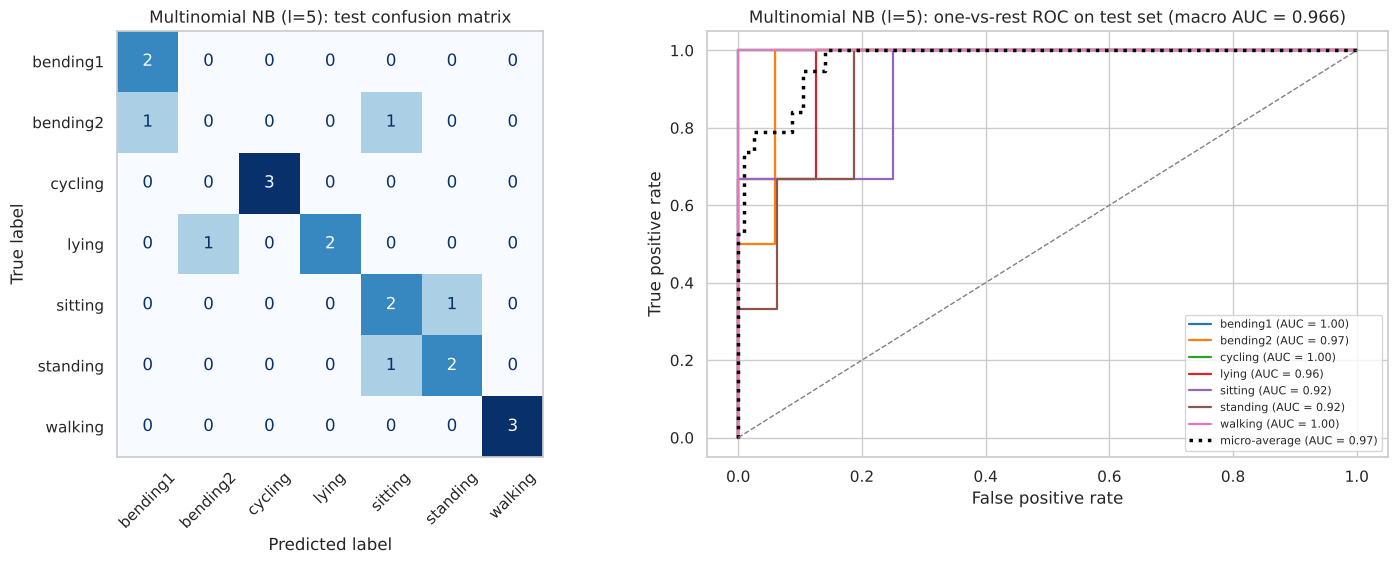

Multinomial NB (l=5): train accuracy = 0.8841, test accuracy = 0.7368, TEST ERROR = 0.2632


In [20]:
nb_results = {}
for name, make in nb_models.items():
    l = best_l_nb[name]
    X = features_for(l)
    model = make().fit(X[train_mask], y_train_multi)
    nb_results[name] = (l, cv_nb.loc[l, name]) + multiclass_report(model, X[train_mask], X[test_mask], f"{name} (l={l})")

#### iii. Which method is better for multi-class classification in this problem?

In [21]:
summary = pd.DataFrame({
    "best l": [best_l_multi] + [nb_results[n][0] for n in nb_models],
    "CV accuracy": [best_acc_multi] + [nb_results[n][1] for n in nb_models],
    "test error": [err_multi_l1] + [nb_results[n][2] for n in nb_models],
    "test macro AUC": [auc_multi_l1] + [nb_results[n][3] for n in nb_models],
}, index=["L1 multinomial regression"] + list(nb_models))
summary.round(4)

,best l,CV accuracy,test error,test macro AUC
L1 multinomial regression,2,0.9143,0.1579,0.9468
Gaussian NB,1,0.8692,0.1053,0.9643
Multinomial NB,5,0.7527,0.2632,0.9660


- **Multinomial Naïve Bayes is clearly the worst** (lowest CV accuracy 0.75, highest test error 0.26). Its model treats features as counts or frequencies, which does not fit continuous summary statistics such as means and standard deviations.
- **L1-penalized multinomial regression** has the highest CV accuracy (0.914), with test error 0.158 (3 of 19 wrong).
- **Gaussian Naïve Bayes** has the lowest test error, 0.105 (2 of 19 wrong), with CV accuracy 0.869.
- Both methods confuse the static activities: L1 multinomial confuses sitting with standing and bending1, and bending2 with sitting; Gaussian NB confuses lying with sitting, and standing with sitting.

**Conclusion:** On the test set, **Gaussian Naïve Bayes is the best method** in this problem. It has the lowest test error, it is very fast, and it needs no tuning other than l.
However, the difference from L1-penalized multinomial regression is only one test instance, and L1 multinomial has the higher CV accuracy, so the two methods are close. Multinomial NB is not suitable for these features.

## 3. ISLR 4.8.3

*QDA with one feature (p = 1): in class k, $X \sim N(\mu_k, \sigma_k^2)$, with class-specific variances. Prove that the Bayes classifier is not linear, but quadratic.*

The Bayes classifier assigns $x$ to the class with the largest posterior probability

$$p_k(x) = \Pr(Y=k \mid X=x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}, \qquad
f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\!\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The denominator is the same for every class, and the logarithm is increasing, so maximizing $p_k(x)$ is the same as maximizing $\log\big(\pi_k f_k(x)\big)$:

$$\log\big(\pi_k f_k(x)\big) = \log \pi_k - \log\sqrt{2\pi} - \log \sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Dropping the constant $-\log\sqrt{2\pi}$ (the same for all classes) and expanding the square gives the discriminant function

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log \sigma_k + \log \pi_k ,$$

and the Bayes classifier assigns $x$ to the class with the largest $\delta_k(x)$.

- In LDA (Section 4.4.1), $\sigma_1^2 = \dots = \sigma_K^2 = \sigma^2$, so the term $-x^2/(2\sigma^2)$ (and $-\log\sigma$) is the same for every class and can be dropped. Then $\delta_k(x)$ is linear in $x$.
- Here the variances differ, so the coefficient of $x^2$, namely $-1/(2\sigma_k^2)$, **depends on k** and cannot be dropped. $\delta_k(x)$ is therefore a **quadratic** function of $x$.

The decision boundary between classes $k$ and $j$ is where $\delta_k(x) = \delta_j(x)$:

$$\left(\frac{1}{2\sigma_j^2} - \frac{1}{2\sigma_k^2}\right) x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_j}{\sigma_j^2}\right) x
+ \left(\frac{\mu_j^2}{2\sigma_j^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log\frac{\sigma_j \pi_k}{\sigma_k \pi_j}\right) = 0 .$$

When $\sigma_k^2 \neq \sigma_j^2$, the coefficient of $x^2$ is non-zero, so this is a quadratic equation in $x$, not a linear one.
It can have two roots, so a class can occupy an interval $(a, b)$ or the region outside it, which a linear classifier (a single threshold) cannot produce. Therefore the Bayes classifier is **not linear; it is quadratic**.

## 4. ISLR 4.8.7

*Predict whether a company issues a dividend (Yes/No) from last year's percent profit $X$. Given: $\bar X = 10$ for companies that issued a dividend, $\bar X = 0$ for those that did not, $\hat\sigma^2 = 36$ for both, and 80% of companies issued dividends.
Assuming $X$ is normal within each class, find the probability that a company issues a dividend when $X = 4$.*

By Bayes' theorem, with $\pi_{Yes} = 0.8$, $\pi_{No} = 0.2$, $\mu_{Yes} = 10$, $\mu_{No} = 0$, $\sigma^2 = 36$:

$$\Pr(Y=\text{Yes} \mid X=4) = \frac{\pi_{Yes}\, f_{Yes}(4)}{\pi_{Yes}\, f_{Yes}(4) + \pi_{No}\, f_{No}(4)}
= \frac{0.8\, e^{-(4-10)^2/(2\cdot 36)}}{0.8\, e^{-(4-10)^2/(2\cdot 36)} + 0.2\, e^{-(4-0)^2/(2\cdot 36)}}$$

(the common factor $1/\sqrt{2\pi\cdot 36}$ cancels).

$$= \frac{0.8\, e^{-0.5}}{0.8\, e^{-0.5} + 0.2\, e^{-0.2222}} = \frac{0.8 \times 0.6065}{0.8 \times 0.6065 + 0.2 \times 0.8007} = \frac{0.4852}{0.4852 + 0.1601} \approx \mathbf{0.752}$$

So the probability that a company with $X = 4$ issues a dividend is about **75.2%**.

In [22]:
from scipy.stats import norm
num = 0.8 * norm.pdf(4, loc=10, scale=6)
den = num + 0.2 * norm.pdf(4, loc=0, scale=6)
print(f"P(dividend | X = 4) = {num / den:.4f}")

P(dividend | X = 4) = 0.7519
